# 03 Drivers of customer value and cancellation (BQ3): Python version

**BQ3:** Which factors relate to customer value and to order cancellation?

- **Part A, customer value:** which Year 1 behaviours predict a customer's net revenue
  in Year 2? (Spearman correlation, linear regression with robust standard errors)
- **Part B, cancellation:** which order-line characteristics predict that a line is
  later cancelled? (logistic regression, decision tree, out-of-time validation)

Same questions and data as `03_drivers_r.ipynb`; the regression results must agree.
Customer analyses use identified customers only (T7).

## Setup and data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROC = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

Y2_START, Y2_END = "2010-12-01", "2011-12-01"   # Year 1 = before Y2_START; Year 2 = Dec 2010 - Nov 2011

sales = pd.read_parquet(PROC / "sales_clean.parquet")
cancels = pd.read_parquet(PROC / "cancellations.parquet")
prod = sales.loc[sales["line_type"] == "product"].copy()      # T6
canc = cancels.loc[cancels["line_type"] == "product"].copy()  # T5
print(f"Product sales lines: {len(prod):,}   with a customer: {prod['has_customer'].mean():.1%}")

Product sales lines: 1,003,357   with a customer: 77.4%


# Part A: Customer value

**Design.** Features are measured in **Year 1** (Dec 2009 – Nov 2010); the outcome is the
customer's net revenue in **Year 2** (Dec 2010 – Nov 2011). Separating the two windows avoids
the circular result "customers who spend more have higher spend".

| Feature (Year 1) | Meaning |
|---|---|
| `recency_days` | Days from the last purchase to 1 Dec 2010 |
| `frequency` | Number of distinct purchase days |
| `avg_order_value` | Sales of kept orders ÷ number of orders |
| `variety` | Number of distinct products bought |
| `tenure_days` | Days from the first purchase to 1 Dec 2010 (data starts Dec 2009, so capped at about one year) |
| `cancel_share` | Cancelled value ÷ gross sales |
| `is_uk` | 1 if most of the customer's lines are from the UK |

In [2]:
ref = pd.Timestamp(Y2_START)
y1 = prod.loc[prod["has_customer"] & (prod["invoice_date"] < Y2_START)]
y2 = prod.loc[prod["has_customer"] & (prod["invoice_date"] >= Y2_START) & (prod["invoice_date"] < Y2_END)]
c1 = canc.loc[canc["customer_id"].notna() & (canc["invoice_date"] < Y2_START)]
c2 = canc.loc[canc["customer_id"].notna() & (canc["invoice_date"] >= Y2_START) & (canc["invoice_date"] < Y2_END)]

feat = y1.groupby("customer_id").agg(
    first_buy=("invoice_date", "min"), last_buy=("invoice_date", "max"),
    frequency=("date", "nunique"), variety=("stock_code", "nunique"),
    gross_y1=("revenue", "sum"), uk_share=("is_uk", "mean"))
kept1 = y1.loc[~y1["cancelled_exact"]].groupby("customer_id").agg(
    kept_sales=("revenue", "sum"), orders=("invoice", "nunique"))
feat = feat.join(kept1)
feat["cancel_y1"] = (-c1.groupby("customer_id")["revenue"].sum()).reindex(feat.index).fillna(0)
feat["recency_days"] = (ref - feat["last_buy"]).dt.days
feat["tenure_days"] = (ref - feat["first_buy"]).dt.days
feat["avg_order_value"] = feat["kept_sales"] / feat["orders"]
feat["cancel_share"] = (feat["cancel_y1"] / feat["gross_y1"]).clip(upper=1)
feat["is_uk"] = (feat["uk_share"] >= 0.5).astype(int)

gross2 = y2.groupby("customer_id")["revenue"].sum()
canc2 = -c2.groupby("customer_id")["revenue"].sum()
net2 = gross2.sub(canc2, fill_value=0)
feat["value_y2"] = net2.reindex(feat.index).fillna(0).clip(lower=0)

before = len(feat)
feat = feat.dropna(subset=["avg_order_value"])     # customers whose every order was cancelled
print(f"Year 1 customers: {before:,}   used: {len(feat):,} (dropped {before - len(feat)} with no kept orders)")
print(f"Bought again in Year 2: {(feat['value_y2'] > 0).mean():.1%}")
print(f"Year 2 net revenue per customer: median £{feat['value_y2'].median():,.0f}, "
      f"mean £{feat['value_y2'].mean():,.0f}")
feat[["recency_days", "frequency", "avg_order_value", "variety", "tenure_days",
      "cancel_share", "is_uk", "value_y2"]].describe().T

Year 1 customers: 4,239   used: 4,227 (dropped 12 with no kept orders)
Bought again in Year 2: 63.8%
Year 2 net revenue per customer: median £308, mean £1,544


,count,mean,std,min,25%,50%,75%,max
recency_days,"4,227.000",86.548,94.629,0.000,15.000,47.000,131.000,364.000
frequency,"4,227.000",3.830,5.744,1.000,1.000,2.000,4.000,117.000
avg_order_value,"4,227.000",374.455,502.987,1.550,177.753,285.300,421.438,"11,880.840"
variety,"4,227.000",63.051,84.334,1.000,17.000,38.000,78.000,"1,712.000"
tenure_days,"4,227.000",217.982,117.311,0.000,114.000,245.000,320.000,364.000
cancel_share,"4,227.000",0.021,0.074,0.000,0.000,0.000,0.014,1.000
is_uk,"4,227.000",0.924,0.265,0.000,1.000,1.000,1.000,1.000
value_y2,"4,227.000","1,544.438","8,023.793",0.000,0.000,308.480,"1,230.275","267,050.000"


## A1. Correlation (Spearman)

Spearman correlation uses ranks, so it is robust to the heavy skew in customer spend and
captures any monotonic relationship, not only straight lines.

                 recency_days  frequency  avg_order_value  variety  tenure_days  cancel_share  is_uk  value_y2
recency_days            1.000     -0.490           -0.150   -0.410        0.120        -0.170  0.010    -0.430
frequency              -0.490      1.000            0.200    0.650        0.580         0.420  0.030     0.570
avg_order_value        -0.150      0.200            1.000    0.430        0.080         0.170 -0.180     0.370
variety                -0.410      0.650            0.430    1.000        0.340         0.290 -0.040     0.480
tenure_days             0.120      0.580            0.080    0.340        1.000         0.270  0.040     0.240
cancel_share           -0.170      0.420            0.170    0.290        0.270         1.000 -0.040     0.280
is_uk                   0.010      0.030           -0.180   -0.040        0.040        -0.040  1.000    -0.070
value_y2               -0.430      0.570            0.370    0.480        0.240         0.280 -0.070     1.000


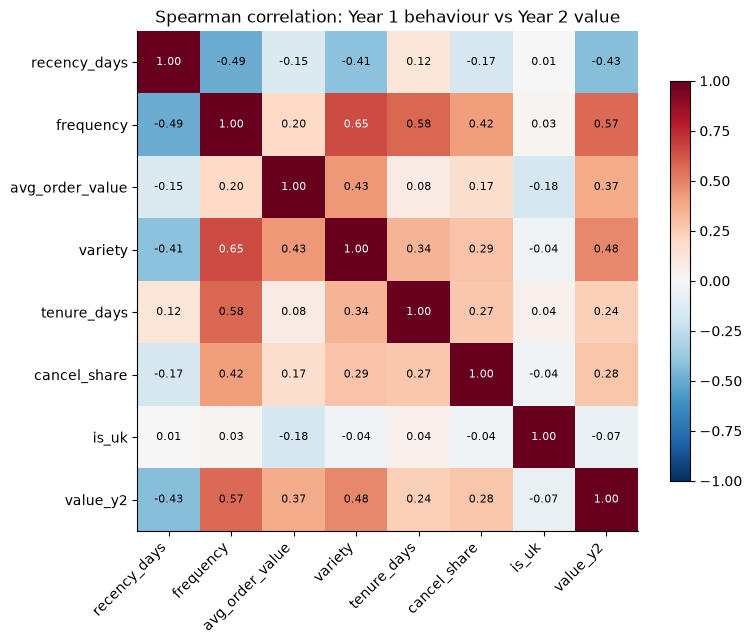

In [3]:
cols = ["recency_days", "frequency", "avg_order_value", "variety",
        "tenure_days", "cancel_share", "is_uk", "value_y2"]
corr = feat[cols].corr(method="spearman")
print(corr.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="black" if abs(corr.iloc[i, j]) < 0.6 else "white")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlation: Year 1 behaviour vs Year 2 value")
fig.tight_layout(); fig.savefig(FIG / "bq3_correlation.png", dpi=150)
plt.show()

## A2. Preparing the predictors and checking multicollinearity

Skewed features are logged, then all continuous predictors are **standardised** (mean 0,
standard deviation 1), so their coefficients are comparable.

The **variance inflation factor (VIF)** shows how much a predictor overlaps with the others.
Below 5 is comfortable; above 10 makes coefficients unreliable. Predictors above 10 are
removed one at a time, highest first, until all are below 10.

In [4]:
m = pd.DataFrame(index=feat.index)
m["recency"] = np.log1p(feat["recency_days"])
m["frequency"] = np.log(feat["frequency"])
m["order_value"] = np.log(feat["avg_order_value"])
m["variety"] = np.log(feat["variety"])
m["tenure"] = feat["tenure_days"]
m["cancel_share"] = feat["cancel_share"]
m = (m - m.mean()) / m.std()                      # standardise (sample standard deviation)
m["is_uk"] = feat["is_uk"]
m["log_value_y2"] = np.log1p(feat["value_y2"])

def vif_table(cols):
    X = sm.add_constant(m[cols])
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                     index=cols, name="VIF")

predictors = ["recency", "frequency", "order_value", "variety", "tenure", "cancel_share", "is_uk"]
print("VIF, all predictors:\n" + vif_table(predictors).round(2).to_string())
removed = []
while (v := vif_table(predictors)).max() > 10:
    removed.append(v.idxmax())
    predictors.remove(v.idxmax())
print(f"\nRemoved for multicollinearity: {removed if removed else 'none'}")
print("VIF, final predictors:\n" + vif_table(predictors).round(2).to_string())

VIF, all predictors:
recency        2.000
frequency      3.370
order_value    1.340
variety        2.010
tenure         2.180
cancel_share   1.020
is_uk          1.050

Removed for multicollinearity: none
VIF, final predictors:
recency        2.000
frequency      3.370
order_value    1.340
variety        2.010
tenure         2.180
cancel_share   1.020
is_uk          1.050


## A3. Linear regression: what predicts next-year value?

- **Outcome:** `log(1 + Year 2 net revenue)`. The log reduces skew; the `1 +` keeps customers
  who did not return (value 0).
- **Robust (HC3) standard errors:** the spread of residuals differs between small and large
  customers (heteroskedasticity), which ordinary standard errors ignore.
- **Effect:** `exp(coef) − 1` ≈ % difference in next-year value per standard deviation
  (for `is_uk`: UK vs non-UK).

In [5]:
ols = smf.ols("log_value_y2 ~ " + " + ".join(predictors), data=m).fit(cov_type="HC3")
coef = pd.DataFrame({"coef": ols.params, "robust_se": ols.bse, "p_value": ols.pvalues})
coef["effect_per_sd"] = np.exp(coef["coef"]) - 1
print(coef.drop("Intercept").to_string(formatters={"effect_per_sd": "{:+.1%}".format}))
print(f"\nCustomers: {int(ols.nobs):,}   R-squared: {ols.rsquared:.3f}   adjusted: {ols.rsquared_adj:.3f}")

               coef  robust_se  p_value effect_per_sd
recency      -0.457      0.062    0.000        -36.7%
frequency     1.531      0.079    0.000       +362.3%
order_value   0.605      0.055    0.000        +83.2%
variety       0.079      0.064    0.218         +8.2%
tenure       -0.185      0.063    0.003        -16.9%
cancel_share -0.008      0.051    0.876         -0.8%
is_uk        -0.430      0.168    0.010        -35.0%

Customers: 4,227   R-squared: 0.347   adjusted: 0.346


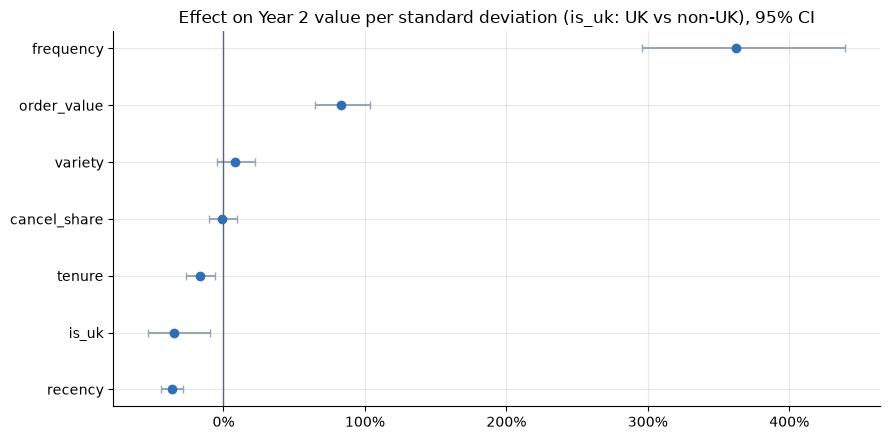

In [6]:
plot = coef.drop("Intercept").copy()
plot["lo"] = np.exp(plot["coef"] - 1.96 * plot["robust_se"]) - 1
plot["hi"] = np.exp(plot["coef"] + 1.96 * plot["robust_se"]) - 1
plot = plot.sort_values("effect_per_sd")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(plot["effect_per_sd"], plot.index,
            xerr=[plot["effect_per_sd"] - plot["lo"], plot["hi"] - plot["effect_per_sd"]],
            fmt="o", color="#2F6FB3", ecolor="#9AA5B1", capsize=3)
ax.axvline(0, color="#5A6676", lw=1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("Effect on Year 2 value per standard deviation (is_uk: UK vs non-UK), 95% CI")
fig.tight_layout(); fig.savefig(FIG / "bq3_value_drivers.png", dpi=150)
plt.show()

# Part B: Cancellation

**Target:** an order line that was later cancelled with an exact match (T5, `cancelled_exact`).
Partial cancellations cannot be linked to a line, so this measures full-line cancellations only.

**Features known when the order is placed:**

| Feature | Meaning |
|---|---|
| `log_qty`, `log_price` | Size and unit price of the line (logged) |
| `log_basket` | Number of lines on the same invoice (logged) |
| `log_prior_orders` | How many earlier orders the customer had placed (log of 1 + count) |
| `is_uk`, `q4`, `late_hour` | UK customer; October–December; ordered at 16:00 or later |
| `is_price_outlier` | Price far from the product's usual price (T16) |

**Out-of-time validation:** the models learn on Year 1 lines and are tested on Year 2 lines,
the standard check for scorecards. Lines from December 2011 are excluded because their
cancellations may fall after the data ends.

In [7]:
lines = prod.loc[prod["has_customer"] & (prod["invoice_date"] < Y2_END)].copy()
lines["basket_lines"] = lines.groupby("invoice")["stock_code"].transform("size")

invoices = (lines.groupby(["customer_id", "invoice"], as_index=False)["invoice_date"].min()
                 .sort_values(["customer_id", "invoice_date", "invoice"]))
invoices["prior_orders"] = invoices.groupby("customer_id").cumcount()
lines = lines.merge(invoices[["invoice", "prior_orders"]], on="invoice", how="left")

lines["cancelled"] = lines["cancelled_exact"].astype(int)
lines["log_qty"] = np.log(lines["quantity"])
lines["log_price"] = np.log(lines["price"])
lines["log_basket"] = np.log(lines["basket_lines"])
lines["log_prior_orders"] = np.log1p(lines["prior_orders"])
lines["is_uk"] = lines["is_uk"].astype(int)
lines["q4"] = lines["invoice_date"].dt.month.isin([10, 11, 12]).astype(int)
lines["late_hour"] = (lines["hour"] >= 16).astype(int)
lines["is_price_outlier"] = lines["is_price_outlier"].astype(int)

features = ["log_qty", "log_price", "log_basket", "log_prior_orders",
            "is_uk", "q4", "late_hour", "is_price_outlier"]
train = lines.loc[lines["invoice_date"] < Y2_START]
test = lines.loc[lines["invoice_date"] >= Y2_START]
print(f"Train (Year 1): {len(train):,} lines, cancel rate {train['cancelled'].mean():.2%}")
print(f"Test  (Year 2): {len(test):,} lines, cancel rate {test['cancelled'].mean():.2%}")

Train (Year 1): 385,443 lines, cancel rate 0.88%
Test  (Year 2): 374,189 lines, cancel rate 0.74%


## B1. Logistic regression

Coefficients are shown as **odds ratios**: 1.5 means the odds of cancellation are 50% higher
per unit of the feature (one log-unit for logged features, e.g. roughly 2.7 times the quantity).

Performance on the Year 2 test set: **AUC**, **Gini** (= 2 × AUC − 1) and **KS**
(maximum gap between the cumulative distributions of cancelled and kept lines).

In [8]:
def performance(y, score):
    auc = roc_auc_score(y, score)
    fpr, tpr, _ = roc_curve(y, score)
    return auc, 2 * auc - 1, np.max(tpr - fpr)

logit = smf.logit("cancelled ~ " + " + ".join(features), data=train).fit(disp=0)
ci = np.exp(logit.conf_int())
odds = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": ci[0], "ci_high": ci[1],
                     "p_value": logit.pvalues}).drop("Intercept")
print(odds.to_string())

p_logit = logit.predict(test)
auc, gini, ks = performance(test["cancelled"], p_logit)
print(f"\nLogistic regression, Year 2 test: AUC {auc:.3f}   Gini {gini:.3f}   KS {ks:.3f}")

                  odds_ratio  ci_low  ci_high  p_value
log_qty                1.091   1.054    1.130    0.000
log_price              1.644   1.572    1.719    0.000
log_basket             0.654   0.628    0.681    0.000
log_prior_orders       1.012   0.984    1.042    0.399
is_uk                  0.513   0.465    0.566    0.000
q4                     0.796   0.739    0.857    0.000
late_hour              1.154   1.044    1.275    0.005
is_price_outlier      17.788  13.007   24.326    0.000

Logistic regression, Year 2 test: AUC 0.677   Gini 0.355   KS 0.261


## B2. Decision tree

A shallow tree (depth 3, at least 500 lines per leaf) gives readable rules. Classes are
balanced in training, because only about 1% of lines are cancelled.

Decision tree, Year 2 test: AUC 0.631   Gini 0.262   KS 0.201

|--- log_price <= 1.59
|   |--- log_basket <= 3.45
|   |   |--- is_uk <= 0.50
|   |   |   |--- class: 1
|   |   |--- is_uk >  0.50
|   |   |   |--- class: 0
|   |--- log_basket >  3.45
|   |   |--- log_qty <= 4.84
|   |   |   |--- class: 0
|   |   |--- log_qty >  4.84
|   |   |   |--- class: 1
|--- log_price >  1.59
|   |--- log_price <= 2.19
|   |   |--- log_basket <= 3.65
|   |   |   |--- class: 1
|   |   |--- log_basket >  3.65
|   |   |   |--- class: 1
|   |--- log_price >  2.19
|   |   |--- log_qty <= 0.35
|   |   |   |--- class: 1
|   |   |--- log_qty >  0.35
|   |   |   |--- class: 1

       lines cancel_rate
leaf                    
7       1085       5.07%
13      7266       4.16%
14     10026       2.39%
3      12147       2.25%
10     33429       1.57%
11     20004       1.09%
4     131890       0.87%
6     169596       0.36% 

Feature importance:
log_price          0.493
log_basket         0.312
log_qty         

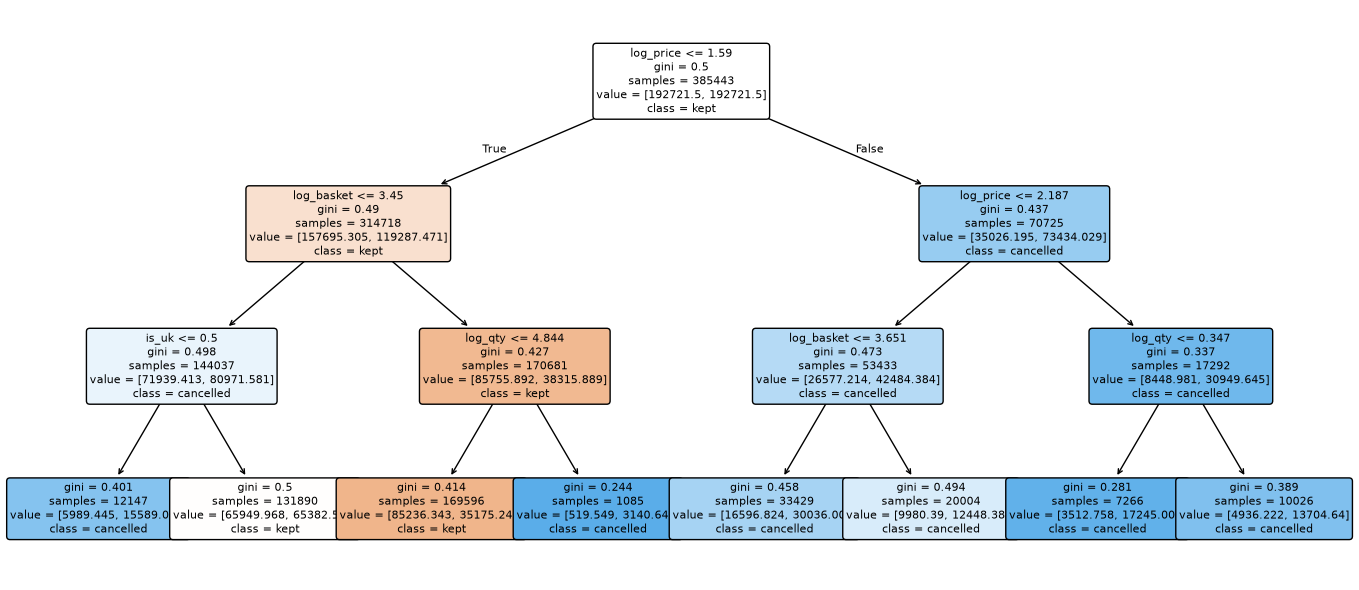

In [9]:
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=500,
                              class_weight="balanced", random_state=42)
tree.fit(train[features], train["cancelled"])
p_tree = tree.predict_proba(test[features])[:, 1]
auc_t, gini_t, ks_t = performance(test["cancelled"], p_tree)
print(f"Decision tree, Year 2 test: AUC {auc_t:.3f}   Gini {gini_t:.3f}   KS {ks_t:.3f}\n")
print(export_text(tree, feature_names=features, decimals=2))

# Cancellation rate in each leaf (training data): easier to read than the class labels
leaves = (pd.DataFrame({"leaf": tree.apply(train[features]), "cancelled": train["cancelled"]})
            .groupby("leaf").agg(lines=("cancelled", "size"), cancel_rate=("cancelled", "mean"))
            .sort_values("cancel_rate", ascending=False))
print(leaves.to_string(formatters={"cancel_rate": "{:.2%}".format}), "\n")

importance = pd.Series(tree.feature_importances_, index=features).sort_values(ascending=False)
print("Feature importance:\n" + importance.round(3).to_string())

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(tree, feature_names=features, class_names=["kept", "cancelled"],
          filled=True, rounded=True, fontsize=8, ax=ax)
fig.tight_layout(); fig.savefig(FIG / "bq3_cancellation_tree.png", dpi=150)
plt.show()

## B3. Comparing the models

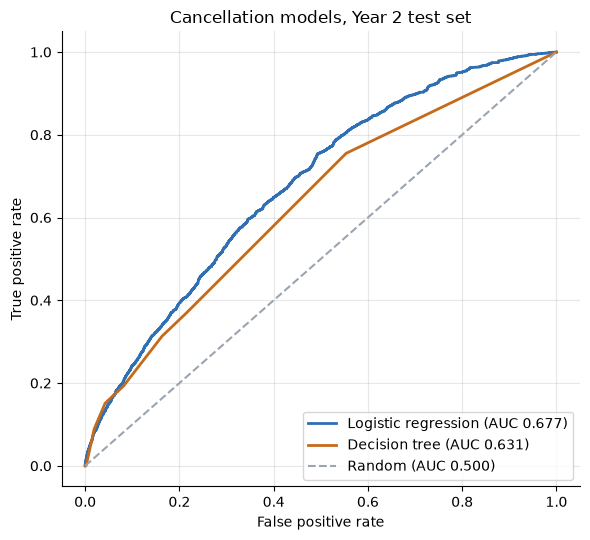

In [10]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for name, score, colour in [("Logistic regression", p_logit, "#2F6FB3"),
                            ("Decision tree", p_tree, "#C46A1A")]:
    fpr, tpr, _ = roc_curve(test["cancelled"], score)
    ax.plot(fpr, tpr, color=colour, lw=2,
            label=f"{name} (AUC {roc_auc_score(test['cancelled'], score):.3f})")
ax.plot([0, 1], [0, 1], color="#9AA5B1", ls="--", label="Random (AUC 0.500)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Cancellation models, Year 2 test set")
ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "bq3_roc.png", dpi=150)
plt.show()

## Export for the dashboard

In [11]:
DASH = ROOT / "reports" / "dashboard_data"
DASH.mkdir(parents=True, exist_ok=True)

value_out = coef.drop("Intercept")[["coef", "robust_se", "p_value", "effect_per_sd"]]
value_out.index.name = "driver"
value_out.round(4).to_csv(DASH / "value_drivers.csv")

odds_out = odds.copy()
odds_out.index.name = "feature"
odds_out.round(4).to_csv(DASH / "cancellation_odds.csv")

pd.DataFrame({"model": ["Logistic regression", "Decision tree"],
              "auc": [auc, auc_t], "gini": [gini, gini_t], "ks": [ks, ks_t]}
             ).round(4).to_csv(DASH / "cancellation_model_performance.csv", index=False)

for f in ["value_drivers.csv", "cancellation_odds.csv", "cancellation_model_performance.csv"]:
    print(f"{f:<36} {len(pd.read_csv(DASH / f)):>3} rows")

value_drivers.csv                      7 rows
cancellation_odds.csv                  8 rows
cancellation_model_performance.csv     2 rows
